# I ACCEPT THE HONOUR CODE

# Imports

In [1]:
#Resuing import code from Lab 2 (Tutoral_DP_Accounting.ipynb)

! pip install dp-accounting

import numpy as np
import dp_accounting
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import optimize as opt
import torch
from torchvision import datasets
import torch.nn.functional as F

sns.set_style('darkgrid')

from dp_accounting import dp_event as event
from dp_accounting.pld import pld_privacy_accountant as pld
from dp_accounting.rdp import rdp_privacy_accountant as rdp

# 1. Batch Sizes in Private Optimization: Signal to Noise ratio

In [2]:
# Function to calculate noise multiplier using RDPAccountant, given training and privacy parameters
# Code  borrowed from Lab2 (Tutoral_DP_Accounting.ipynb))

def get_noise_multiplier(target_epsilon, target_delta, sampling, step):
    RDP_ORDERS = (
        [1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 3.0, 3.5, 4.0, 4.5]
        + list(range(5, 64))
        + [128, 256, 512]
    )
    def objective(noise_multiplier):
        accountant = rdp.RdpAccountant(RDP_ORDERS)
        dpevent = event.SelfComposedDpEvent(
            event.PoissonSampledDpEvent(
                sampling, event.GaussianDpEvent(noise_multiplier)
            ),
            step,
        )
        accountant.compose(dpevent)
        eps = accountant.get_epsilon(target_delta)
        return eps - target_epsilon

    optimal_noise = opt.brentq(objective, 1e-6, 1000)
    return optimal_noise

In [3]:
# Training Parameters

n = 60000
delta = 1/np.power(n, 1.1)
T = 2400
epsilon_vals = [2, 8, 32, 128]

# Varying batch sizes
batch_sizes = [np.power(2, x) for x in [6, 7, 8, 9, 10, 11, 12, 13]]

In [4]:
# Calculating the noise multiplier value as batch size is varied

r_dict = {}

for epsilon in (epsilon_vals):
    r_values = []
    for batch_size in (batch_sizes):
        sampling = batch_size/n                                     # Sampling probability 
        sigma = get_noise_multiplier(epsilon, delta, sampling, T)
        r = sigma/batch_size
        r_values.append (r)
        r_dict[epsilon] = r_values




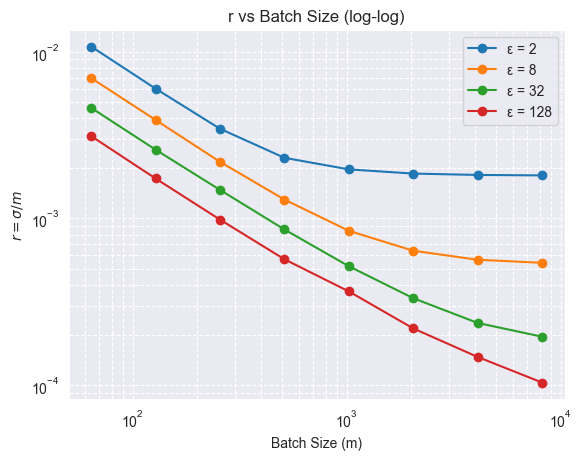

In [5]:
#Plotting r_values vs batch_sizes in log log scale for the required epsilon values

for epsilon, r_values in r_dict.items():
    plt.loglog(batch_sizes, r_values, marker='o', label=f"ε = {epsilon}")

plt.xlabel("Batch Size (m)")
plt.ylabel(r"$r = \sigma / m$")
plt.title("r vs Batch Size (log-log)")
plt.legend()
plt.grid(True, which="both", ls="--")

plt.show()

Q1) Calculating the slope of the log-log plots for the required epsilon values

In [6]:
# Determining the slope of the linear region
# if slope < 0.7 * (initial slope) => end of linear region

def linear_slope (x_list, y_list):
    initial_slope = (y_list[1] - y_list[0])/(x_list[1] - x_list[0])

    linear_idx = 0

    for i in range (2, len (x_list)):

        slope = (y_list[i] - y_list[i-1])/(x_list[i] - x_list[i-1])
        print ("\n"*4)
        
        if ((slope/initial_slope)<0.7):
            linear_idx = i
            
            break

    x_relevant =  (x_list[:linear_idx])
    y_relevant =  (y_list[:linear_idx])

    slope, intercept = np.polyfit(x_relevant, y_relevant, 1)
    
    return slope, intercept, linear_idx



In [7]:
# Determining the slope, optimal batch size for the required epsilon values

opt_batch_size_dict = {}
slope_dict = {}

for epsilon in (epsilon_vals):
    r_values = r_dict[epsilon]
    slope, intercept, linear_idx = linear_slope(np.log(batch_sizes), np.log (r_values))
    slope_dict[epsilon] = slope
    opt_batch_size_dict[epsilon] = batch_sizes[linear_idx]

print (slope_dict)

















































































{2: np.float64(-0.8188071301100897), 8: np.float64(-0.7672933103396133), 32: np.float64(-0.7632699153385275), 128: np.float64(-0.7627570364890978)}


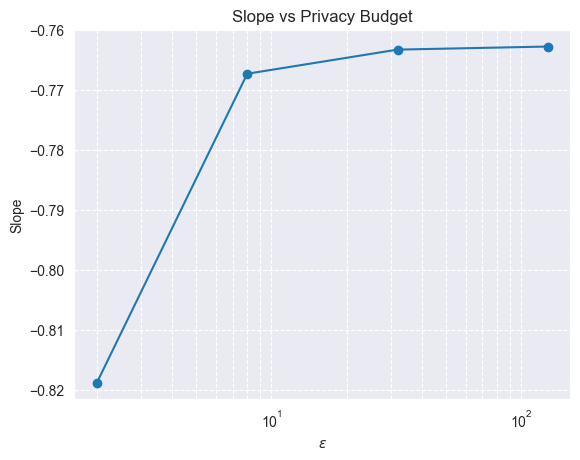

In [8]:
# Plotting slope vs epsilon

epsilons = sorted(slope_dict.keys())           # Converting the dictionary into a list
slopes = [slope_dict[e] for e in epsilons]

plt.figure()

plt.semilogx(epsilons, slopes, marker='o')

plt.xlabel(r"$\epsilon$")
plt.ylabel("Slope")
plt.title("Slope vs Privacy Budget")

plt.grid(True, which="both", ls="--")

plt.show()

Q2) Approximate value of the optimal batch size vs epsilon

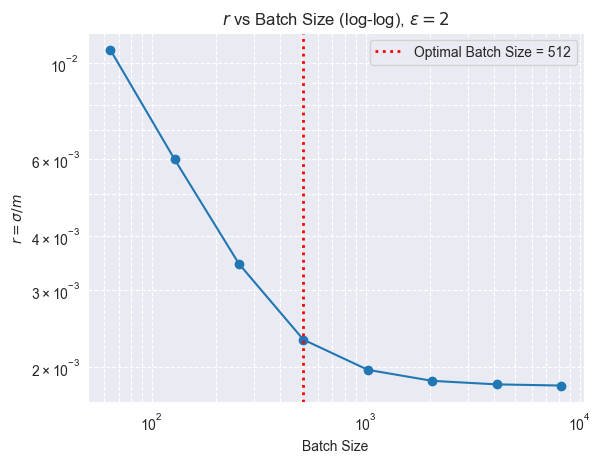

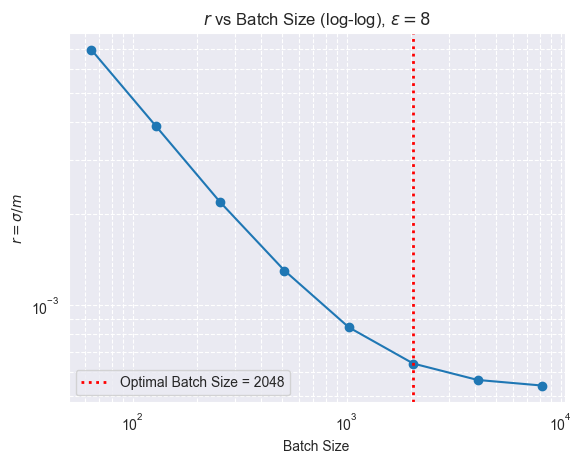

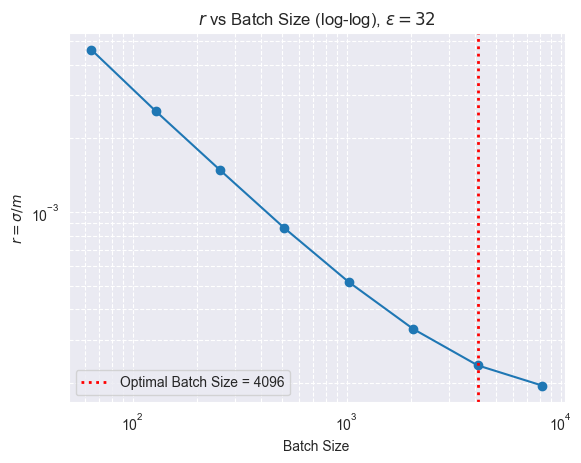

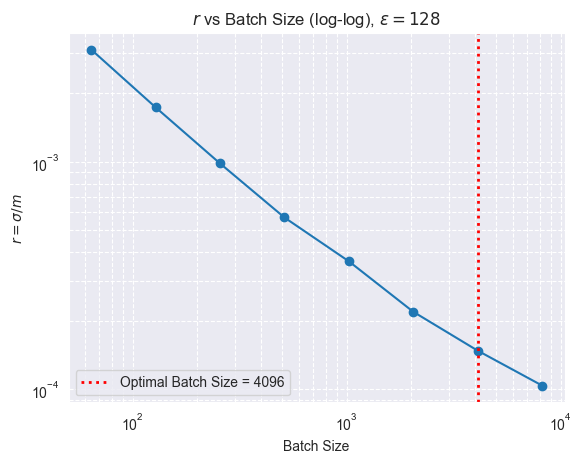

In [9]:
for epsilon in (epsilon_vals):

    optimal_batch_size = opt_batch_size_dict[epsilon]
    r_vals = r_dict[epsilon]

    plt.figure()

    plt.loglog(batch_sizes, r_vals, marker='o')

    plt.axvline(                                              # vertical red dotted line (for optimal batch size)
        x=optimal_batch_size,
        color='red',
        linestyle=':',
        linewidth=2,
        label=f"Optimal Batch Size = {optimal_batch_size}"
    )

    plt.xlabel("Batch Size")
    plt.ylabel(r"$r = \sigma / m$")
    plt.title(fr"$r$ vs Batch Size (log-log), $\epsilon = {epsilon}$")

    plt.legend()
    plt.grid(True, which="both", ls="--")

    plt.show()


# 2 DP-SGD Implementation: Part 1

In [10]:
#imports

from torch.func import functional_call, vmap, grad

1. Function to compute per-example gradients using PyTorch's vmap function

In [11]:
# Code borrowed from the PyTorch tutorial (link: https://docs.pytorch.org/tutorials/intermediate/per_sample_grads.html)

def compute_per_sample_grads(model, loss_fn, data, targets):
    
    # extract parameters and buffers
    params = {k: v.detach() for k, v in model.named_parameters()}
    buffers = {k: v.detach() for k, v in model.named_buffers()}

    # function that computes loss for ONE sample
    def compute_loss(params, buffers, sample, target):
        batch = sample.unsqueeze(0)
        target = target.unsqueeze(0)

        predictions = functional_call(model, (params, buffers), (batch,))
        loss = loss_fn(predictions, target)
        return loss

    # gradient of loss wrt parameters
    ft_compute_grad = grad(compute_loss)

    # vectorize over batch
    ft_compute_sample_grad = vmap(
        ft_compute_grad,
        in_dims=(None, None, 0, 0)
    )

    per_sample_grads = ft_compute_sample_grad(params, buffers, data, targets)

    return per_sample_grads

2. Function to compute the $\ell_2$ norm of each per-sample gradient.

In [12]:
"""
    Accepts a tensor of shape: (batch_size, d1, d2...)
    Computes the L2 norm of each sample after flatenning everything except batch dimension
    Returns a tensor of shape: (batch_size,)
"""

def l2_norm (per_sample_grads):

    tot_l2_norm_sq = 0

    for key in (per_sample_grads.keys()):
        parameter_gradient= per_sample_grads[key]
        norm_sq = parameter_gradient.square().flatten(1).sum(1)
        tot_l2_norm_sq+=norm_sq
        
    l2_norm = tot_l2_norm_sq.sqrt()

    return l2_norm

3. Per-sample gradient clipping to ensure $\lVert g_i \rVert_2 \le C$ for each training example.

In [13]:
"""
    Computes multiplication factor for ||per_sample_grad||_2 <= C

    input: l2_norm tensor of per-example gradients
    input_shape: (batch_size,)

    output: multiplication factor to ensure clipping
    output_shape: (batch_size,)
"""

def clip_factor(l2_per_sample_gradients, C):
    return torch.minimum(
        torch.ones_like(l2_per_sample_gradients),
        C / (l2_per_sample_gradients + 1e-6)
    )    

In [14]:
# Applies the clipping factor to the per sample gradients

def clipping_per_sample_gradients(per_sample_gradients, clip_factor):
    scaled_sample_gradients = {}

    for name, grad in per_sample_gradients.items():
        scale_shape = (clip_factor.shape[0],) + (1,) * (grad.dim() - 1)
        scaled_sample_gradients[name] = grad * clip_factor.view(scale_shape)

    return scaled_sample_gradients

4. Update step for DPSGD

In [15]:
# Helper functions

#Poisson batch sampling at each iteration

def sample_batch(X, y, p):
    mask = torch.rand(len(X)) < p
    batch_X = X[mask]
    batch_y = y[mask]
    batch_size = mask.sum().item()
    batch_X = batch_X.view(batch_X.shape[0], -1).float()   
    return batch_X, batch_y, batch_size

"""
    I used GPT-5.3 to write the above function.
    prompt:
    I have a labeled dataset, (X, y). I want to form batches of data from the total dataset using the following method:
    1) Iterate over the entire dataset
    2) at each data point, include it in the batch with probability p 
    3) form the batch by sampling data points as given above

    Please make a function which accepts X, y and p as input and returns a batch of data as output

"""

#Summing per-sample grads across a batch

def sum_per_sample_grads(per_sample_gradients):
    summed_gradients = {}
    
    for name, grad in per_sample_gradients.items():
        summed_gradients[name] = grad.sum(dim=0)
    
    return summed_gradients

# Adding Gaussian noise to the summed per sample gradients 

def add_gaussian_noise(summed_per_sample_gradients, sigma, clip_norm):
    noisy_grads = {}
    
    std = sigma * clip_norm
    
    for name, grad in summed_per_sample_gradients.items():
        noise = torch.randn_like(grad) * std
        noisy_grads[name] = grad + noise
        
    return noisy_grads

In [16]:
# Function that performs one DPSGD step

def DPSGD_update (model, loss_fn, X_train, y_train, clip_norm, sigma, lr, p):
    batch_X, batch_y, batch_size = sample_batch(X_train, y_train, p)

    per_sample_gradients = compute_per_sample_grads(model, loss_fn, batch_X, batch_y)

    gradient_l2_norms = l2_norm (per_sample_gradients)

    clip_factors = clip_factor(gradient_l2_norms, clip_norm)

    clipped_sample_gradients = clipping_per_sample_gradients(per_sample_gradients, clip_factors)

    summed_per_sample_gradients = sum_per_sample_grads(clipped_sample_gradients)

    noisy_gradient_sum = add_gaussian_noise(summed_per_sample_gradients, sigma, clip_norm)

    update_vector = {}

    for name, grad in noisy_gradient_sum.items():
        update_vector[name] = grad / batch_size

    # update model params
    with torch.no_grad():
        for name, param in model.named_parameters():
            param -= lr * update_vector[name]

    return model

Using the above function to train our model on MNIST

In [17]:
#Loading the MNIST dataset (code is from PyTorch Tutorial)

train_dataset = datasets.MNIST(root="./data", train=True, download=True)
test_dataset = datasets.MNIST(root="./data", train=False, download=True)

X_train, y_train = train_dataset.data, train_dataset.targets.long()
X_test, y_test = test_dataset.data, test_dataset.targets.long()

In [18]:
# Reshaping X_test to pass it into the model

X_test = X_test.view(X_test.shape[0], -1).float()

In [19]:
#Defining the Neural Network classifier (code is from the PyTorch Tutorial)

class MLP(torch.nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hidden = torch.nn.Linear(input_size, hidden_size)
        self.output = torch.nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = torch.relu(self.hidden(x))
        x = self.output(x)
        x = F.log_softmax(x, dim=1)
        return x


In [20]:
#Defining the loss function

def loss_fn(predictions, targets):
    return F.nll_loss(predictions, targets)

In [21]:
# Training Parameters

n = len(X_train)
p = 100/len(X_train)
T = 2400
eps = 8
delta = 1/np.power(n, 1.1)
sigma = get_noise_multiplier(eps, delta, p, T)
clip_norm = 1
learning_rate = [0.01, 0.1, 1, 10]

In [22]:
# Training Function

def train_dpsgd_model(eta, T, X_train, y_train, X_test, y_test, clip_norm, sigma, p, loss_fn):

    print("\n" * 10)
    print(f"Learning rate = {eta}")

    model = MLP(input_size=28*28, hidden_size=100, output_size=10)

    for i in range(T):

        model = DPSGD_update(model, loss_fn, X_train, y_train, clip_norm, sigma, eta, p)

        if ((i + 1) % 100 == 0 and p<500/60000):

            print("\n")
            print(f"Currently on iteration: {i + 1}")

            with torch.no_grad():
                preds = model(X_test)
                predicted_labels = preds.argmax(dim=1)
                accuracy = (predicted_labels == y_test).float().mean().item()

            print(f"Test Accuracy: {accuracy * 100:.2f}%")


        if ((i + 1) % 10 == 0 and p>500/60000):

            print("\n")
            print(f"Currently on iteration: {i + 1}")

            with torch.no_grad():
                preds = model(X_test)
                predicted_labels = preds.argmax(dim=1)
                accuracy = (predicted_labels == y_test).float().mean().item()

            print(f"Test Accuracy: {accuracy * 100:.2f}%")

    # compute final accuracy
    with torch.no_grad():
        preds = model(X_test)
        predicted_labels = preds.argmax(dim=1)
        final_accuracy = (predicted_labels == y_test).float().mean().item()

    return  final_accuracy

In [23]:
# Grid searching over learning rate values

lr_results_batch_100 = {}
for eta in learning_rate:    
    final_acc = train_dpsgd_model(eta, T, X_train, y_train, X_test, y_test, clip_norm, sigma, p, loss_fn)
    lr_results_batch_100[eta] = final_acc












Learning rate = 0.01


Currently on iteration: 100
Test Accuracy: 24.48%


Currently on iteration: 200
Test Accuracy: 40.55%


Currently on iteration: 300
Test Accuracy: 51.03%


Currently on iteration: 400
Test Accuracy: 58.71%


Currently on iteration: 500
Test Accuracy: 63.76%


Currently on iteration: 600
Test Accuracy: 67.67%


Currently on iteration: 700
Test Accuracy: 70.20%


Currently on iteration: 800
Test Accuracy: 72.17%


Currently on iteration: 900
Test Accuracy: 74.20%


Currently on iteration: 1000
Test Accuracy: 75.64%


Currently on iteration: 1100
Test Accuracy: 77.00%


Currently on iteration: 1200
Test Accuracy: 78.08%


Currently on iteration: 1300
Test Accuracy: 78.86%


Currently on iteration: 1400
Test Accuracy: 79.71%


Currently on iteration: 1500
Test Accuracy: 80.18%


Currently on iteration: 1600
Test Accuracy: 81.02%


Currently on iteration: 1700
Test Accuracy: 81.28%


Currently on iteration: 1800
Test Accuracy: 81.75%


Currently on iteratio



Currently on iteration: 1200
Test Accuracy: 89.24%


Currently on iteration: 1300
Test Accuracy: 89.24%


Currently on iteration: 1400
Test Accuracy: 89.41%


Currently on iteration: 1500
Test Accuracy: 89.61%


Currently on iteration: 1600
Test Accuracy: 89.67%


Currently on iteration: 1700
Test Accuracy: 89.71%


Currently on iteration: 1800
Test Accuracy: 90.13%


Currently on iteration: 1900
Test Accuracy: 89.53%


Currently on iteration: 2000
Test Accuracy: 89.97%


Currently on iteration: 2100
Test Accuracy: 89.98%


Currently on iteration: 2200
Test Accuracy: 89.97%


Currently on iteration: 2300
Test Accuracy: 89.94%


Currently on iteration: 2400
Test Accuracy: 89.99%











Learning rate = 1


Currently on iteration: 100
Test Accuracy: 78.89%


Currently on iteration: 200
Test Accuracy: 78.98%


Currently on iteration: 300
Test Accuracy: 78.95%


Currently on iteration: 400
Test Accuracy: 78.81%


Currently on iteration: 500
Test Accuracy: 81.10%


Currently on iterati

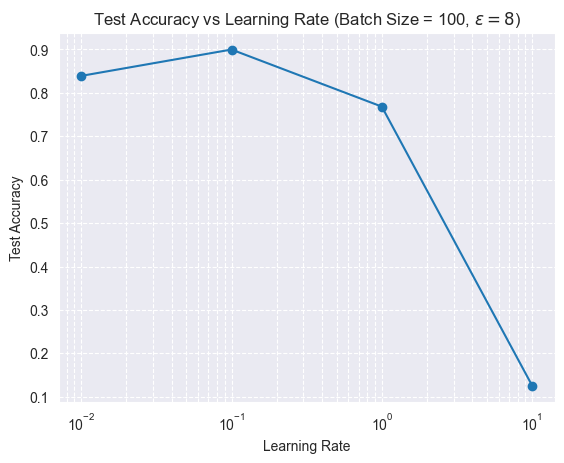

In [24]:
# Plotting final test accuracy against learning rate

lrs = sorted(lr_results_batch_100.keys())
accuracies = [lr_results_batch_100[lr] for lr in lrs]

plt.figure()

plt.semilogx(lrs, accuracies, marker='o')

plt.xlabel("Learning Rate")
plt.ylabel("Test Accuracy")
plt.title(r"Test Accuracy vs Learning Rate (Batch Size = 100, $\epsilon = 8$)")

plt.grid(True, which="both", ls="--")

plt.show()

# 3 DP-SGD: Part2

In [25]:
# Training Parameters

n = len(X_train)
p_heuristic = 2048/len(X_train)            #Suggested by our heuristic
T = 2400
eps = 8
delta = 1/np.power(n, 1.1)
sigma = get_noise_multiplier(eps, delta, p_heuristic, T)
clip_norm = 1
learning_rate = [0.01, 0.1, 1, 10]

In [26]:
# Grid searching over learning rate values

lr_results_batch_heuristic = {}

for eta in learning_rate:    
    final_acc = train_dpsgd_model(eta, T, X_train, y_train, X_test, y_test, clip_norm, sigma, p_heuristic, loss_fn)
    lr_results_batch_heuristic[eta] = final_acc












Learning rate = 0.01


Currently on iteration: 10
Test Accuracy: 18.37%


Currently on iteration: 20
Test Accuracy: 20.98%


Currently on iteration: 30
Test Accuracy: 23.42%


Currently on iteration: 40
Test Accuracy: 25.32%


Currently on iteration: 50
Test Accuracy: 26.67%


Currently on iteration: 60
Test Accuracy: 28.08%


Currently on iteration: 70
Test Accuracy: 29.21%


Currently on iteration: 80
Test Accuracy: 30.55%


Currently on iteration: 90
Test Accuracy: 31.94%


Currently on iteration: 100
Test Accuracy: 33.24%


Currently on iteration: 110
Test Accuracy: 34.49%


Currently on iteration: 120
Test Accuracy: 35.74%


Currently on iteration: 130
Test Accuracy: 37.13%


Currently on iteration: 140
Test Accuracy: 38.43%


Currently on iteration: 150
Test Accuracy: 39.61%


Currently on iteration: 160
Test Accuracy: 40.65%


Currently on iteration: 170
Test Accuracy: 41.76%


Currently on iteration: 180
Test Accuracy: 42.76%


Currently on iteration: 190
Test Accura



Currently on iteration: 830
Test Accuracy: 73.09%


Currently on iteration: 840
Test Accuracy: 73.33%


Currently on iteration: 850
Test Accuracy: 73.46%


Currently on iteration: 860
Test Accuracy: 73.58%


Currently on iteration: 870
Test Accuracy: 73.77%


Currently on iteration: 880
Test Accuracy: 73.98%


Currently on iteration: 890
Test Accuracy: 74.16%


Currently on iteration: 900
Test Accuracy: 74.34%


Currently on iteration: 910
Test Accuracy: 74.48%


Currently on iteration: 920
Test Accuracy: 74.67%


Currently on iteration: 930
Test Accuracy: 74.78%


Currently on iteration: 940
Test Accuracy: 74.88%


Currently on iteration: 950
Test Accuracy: 74.97%


Currently on iteration: 960
Test Accuracy: 75.17%


Currently on iteration: 970
Test Accuracy: 75.29%


Currently on iteration: 980
Test Accuracy: 75.43%


Currently on iteration: 990
Test Accuracy: 75.54%


Currently on iteration: 1000
Test Accuracy: 75.74%


Currently on iteration: 1010
Test Accuracy: 75.84%


Currentl

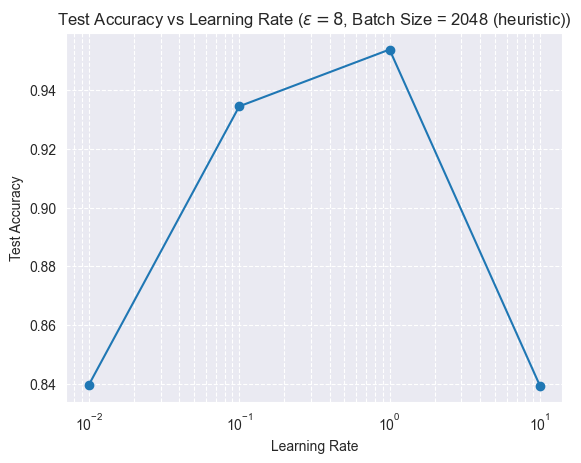

In [27]:
# Plotting final test accuracy against learning rate

lrs = sorted(lr_results_batch_heuristic.keys())                      # Converting the data into lists
accuracies = [lr_results_batch_heuristic[lr] for lr in lrs]

plt.figure()

plt.semilogx(lrs, accuracies, marker='o')

plt.xlabel("Learning Rate")
plt.ylabel("Test Accuracy")
plt.title(r"Test Accuracy vs Learning Rate ($\epsilon = 8$, Batch Size = 2048 (heuristic))")

plt.grid(True, which="both", ls="--")

plt.show()

# Part 4: Privacy Utility Tradeoffs for DP SGD

In [28]:
epsilon_values = [2, 8, 32]
learning_rates = [0.01, 0.1, 1, 10]

In [29]:
#Observing the privacy utility tradeoff for a batch size of 100
# Training Parameters

n = len(X_train)
p = 100/len(X_train)           
T = 2400
delta = 1/np.power(n, 1.1)
clip_norm = 1
learning_rates = [0.01, 0.1, 1, 10]

In [30]:
utility_batch_size_100 = {}

for eps in (epsilon_values):
    
    sigma = get_noise_multiplier(eps, delta, p, T)
    test_acc = []
    for eta in (learning_rates):
        print ("\n"*3)
        print (f"Epsilon = {eps}")
        print (f"Learning rate = {eta}")
        final_acc = train_dpsgd_model(eta, T, X_train, y_train, X_test, y_test, clip_norm, sigma, p, loss_fn)
        test_acc.append(final_acc)

    utility_batch_size_100[eps] = max(test_acc)





Epsilon = 2
Learning rate = 0.01











Learning rate = 0.01


Currently on iteration: 100
Test Accuracy: 28.23%


Currently on iteration: 200
Test Accuracy: 42.07%


Currently on iteration: 300
Test Accuracy: 52.30%


Currently on iteration: 400
Test Accuracy: 59.39%


Currently on iteration: 500
Test Accuracy: 64.52%


Currently on iteration: 600
Test Accuracy: 68.35%


Currently on iteration: 700
Test Accuracy: 70.88%


Currently on iteration: 800
Test Accuracy: 73.05%


Currently on iteration: 900
Test Accuracy: 75.14%


Currently on iteration: 1000
Test Accuracy: 76.64%


Currently on iteration: 1100
Test Accuracy: 77.67%


Currently on iteration: 1200
Test Accuracy: 78.85%


Currently on iteration: 1300
Test Accuracy: 79.96%


Currently on iteration: 1400
Test Accuracy: 80.91%


Currently on iteration: 1500
Test Accuracy: 81.19%


Currently on iteration: 1600
Test Accuracy: 81.69%


Currently on iteration: 1700
Test Accuracy: 82.26%


Currently on iteration: 1800
Test Acc

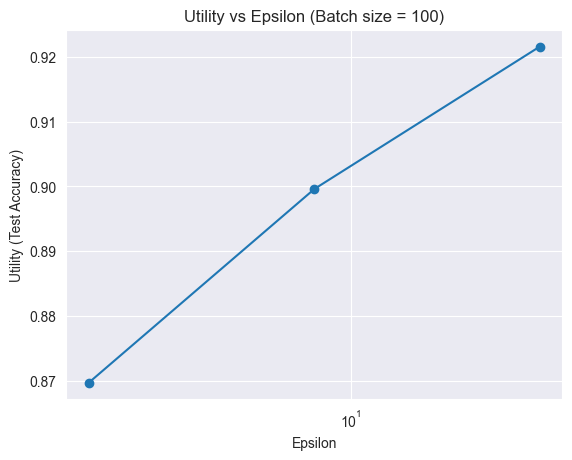

In [31]:
#Plotting ustility vs privacy parameter epsilon

eps = sorted(utility_batch_size_100.keys())             #Converting dict to list
utility = [utility_batch_size_100[e] for e in eps]

plt.figure()
plt.semilogx(eps, utility, marker='o')
plt.xlabel("Epsilon")
plt.ylabel("Utility (Test Accuracy)")
plt.title("Utility vs Epsilon (Batch size = 100)")
plt.grid(True)

plt.show()

Using our Heuristic

In [32]:
#Observing the privacy utility tradeoff for batch size given by our heuristic
# Training Parameters

n = len(X_train)
T = 2400
delta = 1/np.power(n, 1.1)
clip_norm = 1
learning_rates = [0.01, 0.1, 1, 10]

In [33]:
utility_batch_size_heuristic= {}

for eps in (epsilon_values):
    optimal_batch_size = opt_batch_size_dict[eps]
    p = optimal_batch_size/len(X_train)
    sigma = get_noise_multiplier(eps, delta, p, T)
    test_acc = []
    for eta in (learning_rates):
        print ("\n"*3)
        print (f"Epsilon = {eps}")
        print (f"Learning rate = {eta}")
        final_acc = train_dpsgd_model(eta, T, X_train, y_train, X_test, y_test, clip_norm, sigma, p, loss_fn)
        test_acc.append(final_acc)

    utility_batch_size_heuristic[eps] = max(test_acc)





Epsilon = 2
Learning rate = 0.01











Learning rate = 0.01


Currently on iteration: 10
Test Accuracy: 12.33%


Currently on iteration: 20
Test Accuracy: 14.80%


Currently on iteration: 30
Test Accuracy: 16.79%


Currently on iteration: 40
Test Accuracy: 18.20%


Currently on iteration: 50
Test Accuracy: 19.59%


Currently on iteration: 60
Test Accuracy: 20.93%


Currently on iteration: 70
Test Accuracy: 22.33%


Currently on iteration: 80
Test Accuracy: 23.64%


Currently on iteration: 90
Test Accuracy: 25.08%


Currently on iteration: 100
Test Accuracy: 26.58%


Currently on iteration: 110
Test Accuracy: 28.03%


Currently on iteration: 120
Test Accuracy: 29.66%


Currently on iteration: 130
Test Accuracy: 31.23%


Currently on iteration: 140
Test Accuracy: 32.84%


Currently on iteration: 150
Test Accuracy: 34.44%


Currently on iteration: 160
Test Accuracy: 36.00%


Currently on iteration: 170
Test Accuracy: 37.63%


Currently on iteration: 180
Test Accuracy: 39.00%


Cu





Epsilon = 32
Learning rate = 0.01











Learning rate = 0.01


Currently on iteration: 10
Test Accuracy: 15.38%


Currently on iteration: 20
Test Accuracy: 17.03%


Currently on iteration: 30
Test Accuracy: 19.46%


Currently on iteration: 40
Test Accuracy: 21.91%


Currently on iteration: 50
Test Accuracy: 24.15%


Currently on iteration: 60
Test Accuracy: 26.52%


Currently on iteration: 70
Test Accuracy: 28.40%


Currently on iteration: 80
Test Accuracy: 30.55%


Currently on iteration: 90
Test Accuracy: 32.47%


Currently on iteration: 100
Test Accuracy: 34.45%


Currently on iteration: 110
Test Accuracy: 35.90%


Currently on iteration: 120
Test Accuracy: 37.32%


Currently on iteration: 130
Test Accuracy: 38.71%


Currently on iteration: 140
Test Accuracy: 40.08%


Currently on iteration: 150
Test Accuracy: 41.40%


Currently on iteration: 160
Test Accuracy: 42.87%


Currently on iteration: 170
Test Accuracy: 43.71%


Currently on iteration: 180
Test Accuracy: 44.75%


C

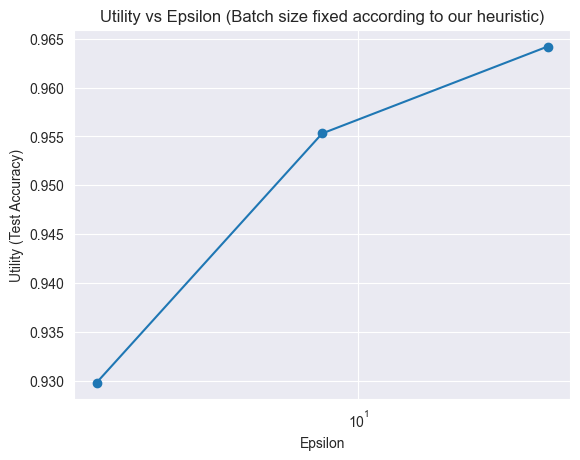

In [34]:
#Plotting ustility vs privacy parameter epsilon

eps = sorted(utility_batch_size_heuristic.keys())             #Converting dict to list
utility = [utility_batch_size_heuristic[e] for e in eps]

plt.figure()
plt.semilogx(eps, utility, marker='o')
plt.xlabel("Epsilon")
plt.ylabel("Utility (Test Accuracy)")
plt.title("Utility vs Epsilon (Batch size fixed according to our heuristic)")
plt.grid(True)

plt.show()

# References

1) PyTorch Documentation
2) Python Documentation
3) Lab 2 on per sample gradients
4) PyTorch Tutorial on per sample gradients 
5) Opacus Documentation for RDPAccountant 
